In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

master_df = pd.read_parquet(
    "../data/processed/master_df.parquet"
)

In [3]:
total_revenue = master_df["total_value"].sum()

total_profit = master_df["profit"].sum()

total_customers = master_df["customer_id"].nunique()

total_products = master_df["sku_id"].nunique()

total_stores = master_df["store_id"].nunique()

print("Revenue:", total_revenue)

print("Profit:", total_profit)

print("Customers:", total_customers)

print("Products:", total_products)

print("Stores:", total_stores)

Revenue: 10902909080.72999
Profit: 3005764315.530005
Customers: 10000
Products: 5000
Stores: 30


Insight:

- The company generated 10.9 billion in revenue over 4 years.
- Profit margin is approximately: 27.6 %

In [7]:
monthly_sales = (
    master_df
    .groupby(["year", "month"])["total_value"]
    .sum()
    .reset_index()
)

In [9]:
monthly_sales["month_year"] = pd.to_datetime(
    monthly_sales[["year", "month"]].assign(day=1)
)

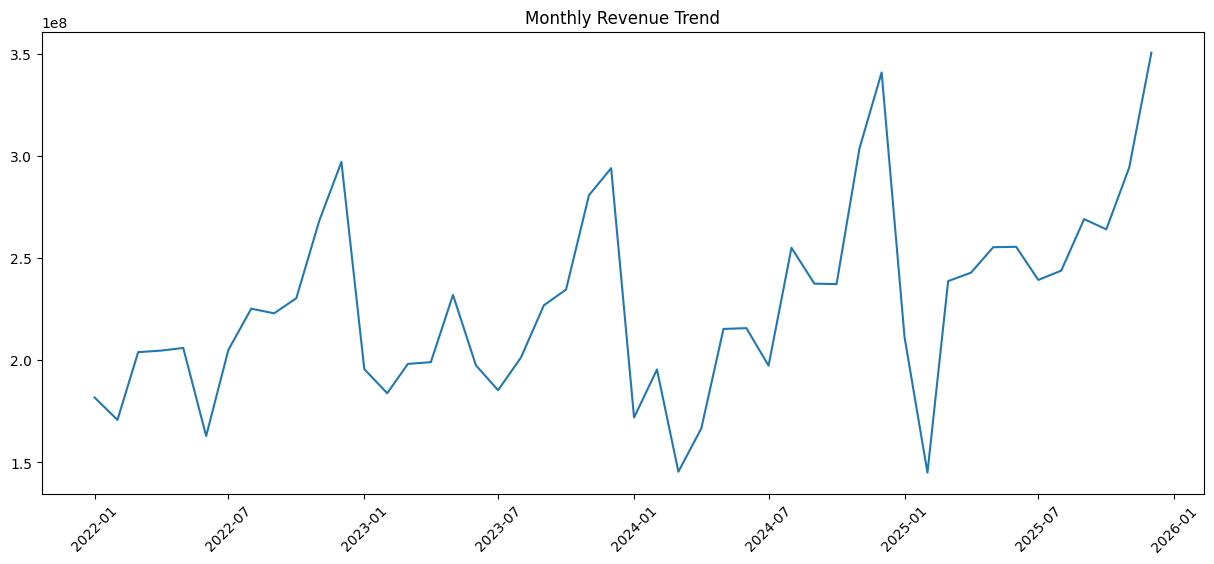

In [47]:
plt.figure(figsize=(15, 6))

plt.plot(

    monthly_sales["month_year"],

    monthly_sales["total_value"]

)

plt.xticks(rotation=45)

plt.title("Monthly Revenue Trend")

plt.savefig(

    "../reports/images/monthly_sales.png",

    bbox_inches="tight"
)

plt.show()

Observations:

- Revenue is increasing year by year.

- Every year, the highest sales are around November–December.

- There is a sharp drop around January–February.

Business interpretation:
- November–December = festival/holiday season.
- January–February = post-holiday slowdown.
- The business has clear seasonality.

In [14]:
category_sales = (

    master_df

    .groupby("category")["total_value"]

    .sum()

    .sort_values(ascending=False)

    .head(10)

)

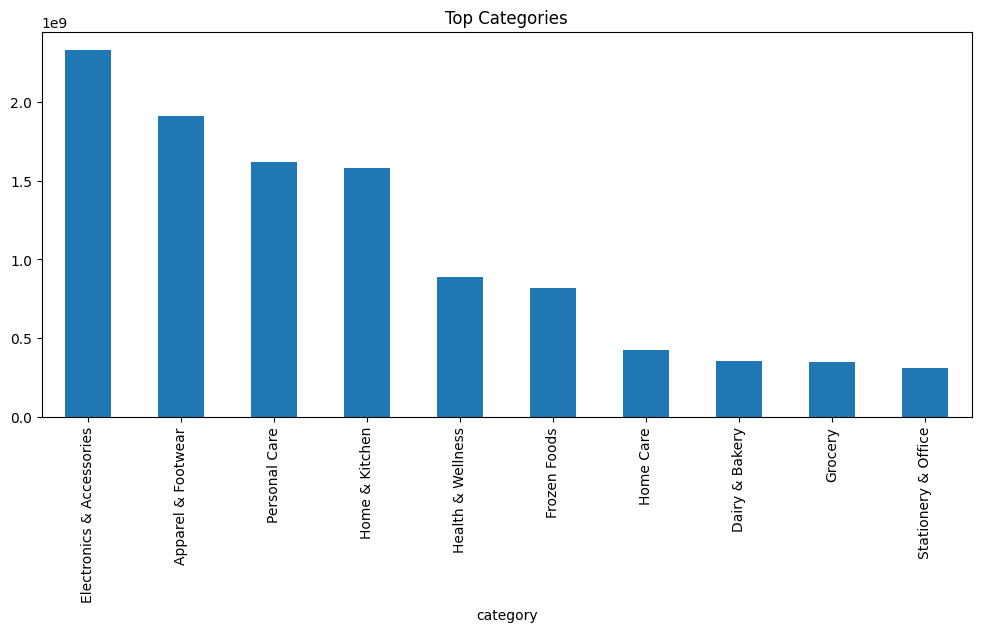

In [49]:
category_sales.plot(

    kind="bar",

    figsize=(12, 5)

)

plt.title("Top Categories")

plt.savefig(
    "../reports/images/top_categories.png",
    bbox_inches="tight"
)

plt.show()

Insight:
- Electronics is the biggest revenue generator.
- Stationery contributes the least.

Business suggestion:

- Increase inventory monitoring for Electronics because stockouts there can cause huge revenue loss.

In [19]:
brand_sales = (

    master_df

    .groupby("brand")["total_value"]

    .sum()

    .sort_values(ascending=False)

    .head(10)

)

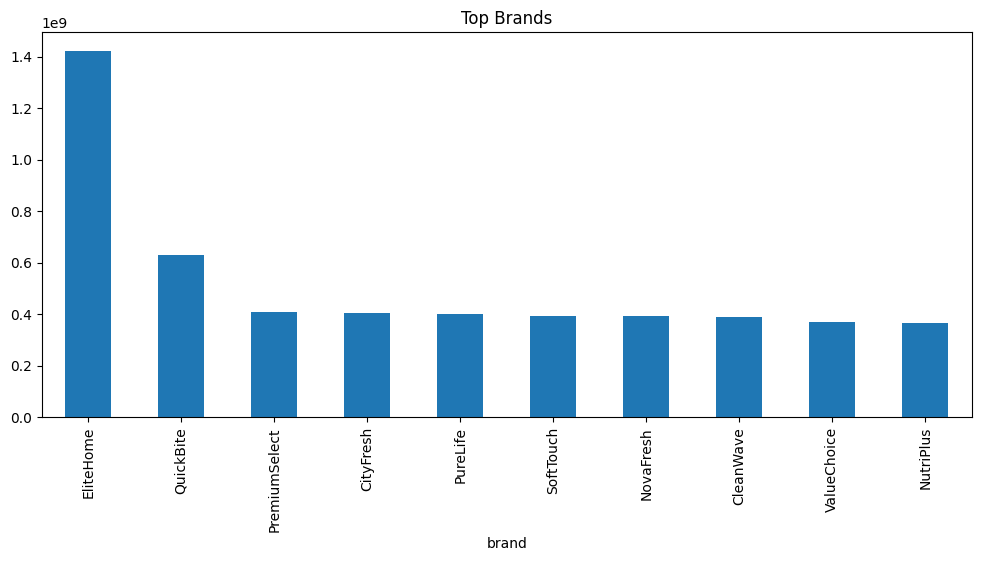

In [51]:
brand_sales.plot(

    kind="bar",

    figsize=(12, 5)

)

plt.title("Top Brands")

plt.savefig(
    "../reports/images/top_brands.png",
    bbox_inches="tight"
)

plt.show()

Insight:

- EliteHome contributes almost twice as much revenue as QuickBite.

This means:

- EliteHome products are likely high-value products.
- Losing inventory of EliteHome products can be dangerous.

In [23]:
channel_sales = (

    master_df

    .groupby("channel")["total_value"]

    .sum()

)

C:\Users\Dell\AppData\Local\Temp\ipykernel_15476\3720439078.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("channel")["total_value"]


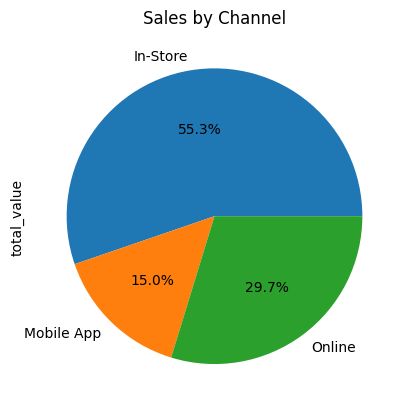

In [53]:
channel_sales.plot(

    kind="pie",

    autopct="%1.1f%%"

)

plt.title("Sales by Channel")

plt.savefig(
    "../reports/images/channel_distribution.png",
    bbox_inches="tight"
)

plt.show()

Insight:
- Physical stores still dominate.
- Online business is strong.
- Mobile app adoption is relatively low.

Recommendation:

- The company should improve app promotions and loyalty rewards.

In [27]:
loyalty_sales = (

    master_df

    .groupby("loyalty_segment")["total_value"]

    .sum()

    .sort_values(ascending=False)

)

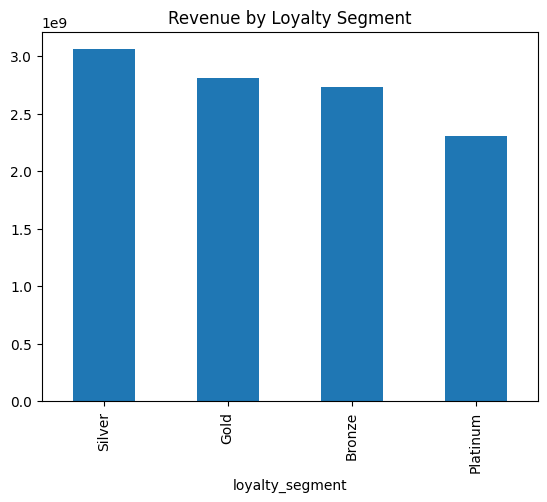

In [55]:
loyalty_sales.plot(

    kind="bar"

)

plt.title("Revenue by Loyalty Segment")

plt.savefig(
    "../reports/images/loyalty_segment_revenue.png",
    bbox_inches="tight"
)

plt.show()

In [61]:
master_df.groupby(
    "loyalty_segment"
)["customer_id"].nunique()

loyalty_segment
Bronze      3969
Gold        1905
Platinum    1020
Silver      3106
Name: customer_id, dtype: int64

In [63]:
master_df.groupby(
    "loyalty_segment"
)["total_value"].mean()

loyalty_segment
Bronze      1093.661341
Gold        1094.273622
Platinum    1094.955375
Silver      1096.104359
Name: total_value, dtype: float64

## Insight

- Silver customers generated the highest total revenue, contributing approximately **3.07 billion**, followed by Gold (**2.82 billion**) and Bronze (**2.74 billion**).

- Although Platinum customers are considered the most loyal segment, they contributed the lowest total revenue (**2.31 billion**) because they represent the smallest customer base (**1,020 customers**).

- The average transaction value across all loyalty segments is nearly identical (around **1094–1096**), indicating that customer spending behavior per transaction does not vary significantly between segments.

- The higher revenue contribution from Silver customers is primarily due to their larger customer base (**3,106 customers**) and potentially higher purchase frequency rather than higher spending per transaction.

- Bronze customers constitute the largest customer segment (**3,969 customers**) but generate less revenue than Silver customers, suggesting lower purchase frequency.

---

## Business Recommendations

- Introduce exclusive offers and loyalty rewards to encourage Silver customers to upgrade to the Gold and Platinum segments.

- Analyze the purchasing behavior of Silver customers and replicate successful engagement strategies across other customer segments.

- Design personalized marketing campaigns for Bronze customers to increase their purchase frequency and overall contribution.

- Offer premium benefits, cashback, and early-access promotions to Platinum customers to maximize revenue from this highly loyal segment.

- Implement targeted retention strategies for Gold and Platinum customers, as retaining loyal customers is generally more cost-effective than acquiring new ones.

- Conduct further analysis on customer purchase frequency and customer lifetime value (CLV) to better understand the factors driving revenue across different loyalty segments.

In [35]:
master_df.columns

Index(['date', 'receipt_id', 'store_id', 'sku_id', 'customer_id', 'quantity',
       'unit_price', 'total_value', 'channel', 'discount_pct', 'promo_id',
       'sku_name', 'category', 'subcategory', 'cost_price', 'brand', 'age',
       'gender', 'city', 'loyalty_segment', 'preferred_channel',
       'registration_date', 'store_name', 'store_type', 'opening_date',
       'promo_name', 'start_date', 'end_date', 'discount_pct_promo',
       'promo_type', 'target_type', 'target_value', 'promo_name_promo',
       'start_date_promo', 'end_date_promo', 'promo_type_promo',
       'target_type_promo', 'target_value_promo', 'year', 'month', 'quarter',
       'day', 'weekday', 'week', 'profit'],
      dtype='object')

In [37]:
city_sales = (

    master_df

    .groupby("city")["total_value"]

    .sum()

    .sort_values(ascending=False)

    .head(10)

)

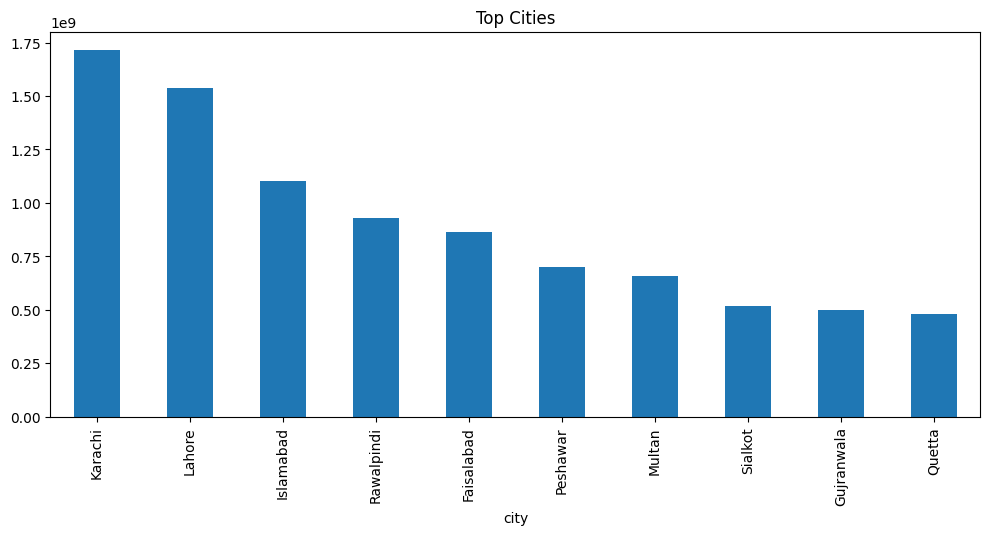

In [57]:
city_sales.plot(

    kind="bar",

    figsize=(12, 5)

)

plt.title("Top Cities")

plt.savefig(
    "../reports/images/top_cities.png",
    bbox_inches="tight"
)

plt.show()

Insight:
- Karachi is the biggest market.
- Lahore is the second biggest market.

Inventory planning for these cities should be prioritized.

In [41]:
promo_sales = master_df[
    master_df["promo_id"].notna()
]

In [43]:
promo_type_sales = (

    promo_sales

    .groupby("promo_type")["total_value"]

    .sum()

)

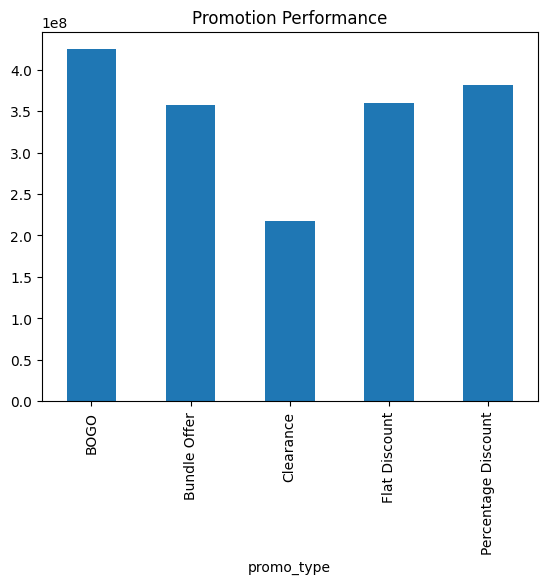

In [59]:
promo_type_sales.plot(

    kind="bar"

)

plt.title("Promotion Performance")

plt.savefig(
    "../reports/images/promotion_performance.png",
    bbox_inches="tight"
)

plt.show()

Insight:

- BOGO promotions generate the highest revenue.

Business recommendation:

- Increase BOGO campaigns during holiday seasons.